# Anguish – Ice (Harakim)

Anguish (Ice) is a single-target debuff that lowers the target's armor and weapon value by the
same amount for 20 s.

| | |
|---|---|
| Class | Harakim |
| Target | Single hostile |
| Cost | 35 mana (the skill description says 30), spent before the roll |
| Cooldown | none: Anguish adds no exhaust (it is refused while exhausted) |
| Landing roll | `chance_base(skill, 10, effective_resist(Resist))` |
| Duration | 20 s |
| Effect | `armor[1]` and `weapon[1]` += $-\operatorname{clamp}(\lfloor p/8 \rfloor, 2, 30)$; the final values are clamped at 0 |
| Source | `server/src/driver/skill/harakim.rs::skill_anguish_ice`, `anguish_preflight`, `attach_anguish`; clamp in `server/src/state/stats.rs` |

---

# Formula

With $p$ the raw modified skill (no Immunity reduction):

$$
d = \operatorname{clamp}\!\left(\lfloor p/8 \rfloor,\ 2,\ 30\right)
\qquad
\text{armor}' = \max(0,\ \text{armor} - d)
\qquad
\text{weapon}' = \max(0,\ \text{weapon} - d)
$$

Each point of armor removed adds 0.25 HP to every landed melee hit on the target and 0.75 HP to
every spell hit (`do_hurt` type 1). Each point of weapon removed takes 0.25 HP off every hit the
target lands, before the defender's armor.

| Quantity | Breakpoint |
|---|---|
| Drop at the raise caps | −13 at 105, −15 at 120 |
| Floor | −2 for $p < 24$ |
| Ceiling | −30 at $p \ge 240$ |
| Uptime | 35 mana per 20 s; a same-power recast refreshes it |

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
COST = 35
DURATION_S = 20

# Model

In [2]:
def drop(p):
    return mm.clamp(mm.idiv(p, 8), 2, 30)


def ally_melee_gain(p, target_armor, wv=40, strength=80):
    """× damage per landed melee hit an ally deals to the debuffed target."""
    base = mm.melee_hit_hp(wv, strength, target_armor)
    after = mm.melee_hit_hp(wv, strength, np.maximum(0, target_armor - drop(p)))
    return np.where(base > 0, after / np.maximum(base, 1e-9), np.nan)


def target_melee_loss(p, target_wv, strength=80, defender_armor=20):
    """Fraction of the debuffed target's damage per landed hit that is removed."""
    base = mm.melee_hit_hp(target_wv, strength, defender_armor)
    if base <= 0:
        return np.full(np.shape(p), np.nan)
    after = np.array([mm.melee_hit_hp(max(0, target_wv - int(d)), strength, defender_armor)
                      for d in np.atleast_1d(drop(p))])
    out = 1 - after / base
    return out if np.ndim(p) else out[0]

# Validation

- `anguish_ice_lowers_armor_and_weapon`: skill 80 → mana 100,000 → 65,000 per attempt, armor and
  weapon −10, the item lasts `TICKS*20` and records the caster.
- `anguish_ice_modifiers_have_a_floor`: skill 8 → −2.

In [3]:
assert 100_000 - COST * 1000 == 65_000
assert drop(80) == 10 and drop(8) == 2 and mm.TICKS * DURATION_S == 720
assert drop(105) == 13 and drop(120) == 15 and drop(239) == 29 and drop(240) == 30
print("Anguish-Ice model OK")

Anguish-Ice model OK


# Plots

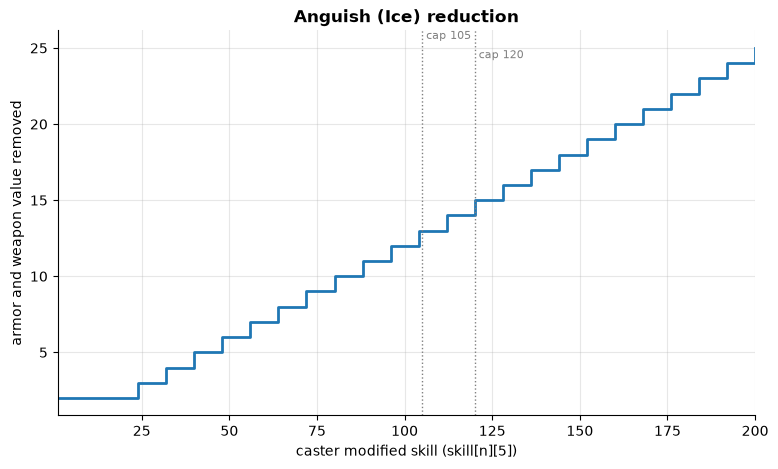

In [4]:
fig, ax = plt.subplots()
ax.step(P, drop(P), where="post")
mm.skill_axis(ax, "armor and weapon value removed", "Anguish (Ice) reduction")
mm.mark_caps(ax)

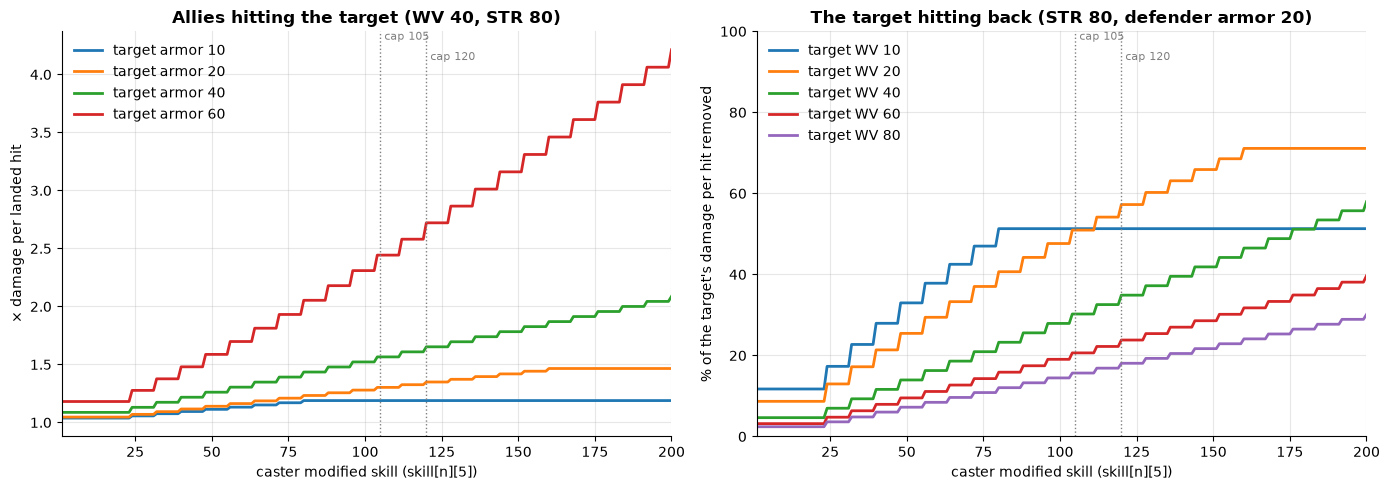

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for armor in (10, 20, 40, 60):
    ax.plot(P, ally_melee_gain(P, armor), label=f"target armor {armor}")
mm.skill_axis(ax, "× damage per landed hit", "Allies hitting the target (WV 40, STR 80)")
mm.mark_caps(ax)
ax.legend()

ax = axes[1]
for wv in mm.WV_SWEEP:
    ax.plot(P, 100 * target_melee_loss(P, wv), label=f"target WV {wv}")
mm.skill_axis(ax, "% of the target's damage per hit removed", "The target hitting back (STR 80, defender armor 20)")
ax.set_ylim(0, 100)
mm.mark_caps(ax)
ax.legend()
plt.tight_layout()

# Observations

- **Nothing grants it today.** As with Anguish (Lava), no talent node or other code path in
  `core/` or `server/` grants `SK_ANGUISH_ICE`. "Elemental Anguish" teaches only Anguish (Earth).
- **A modest, steady debuff.** At skill 105 it removes 13 armor and 13 weapon value. A WV-40 STR-80
  ally then deals ×1.30 per landed hit against armor 20 (10.75 → 14.0 HP) and ×1.57 against armor
  40 (5.75 → 9.0). The gain grows with the target's armor, because a fixed drop is a larger share
  of a small post-armor remainder.
- **The weapon drop matters more than the armor drop.** Against a defender with armor 20 the
  target loses 51% of its damage per hit at WV 20, 30% at WV 40 and 16% at WV 80.
- **It saturates late.** The cap of −30 needs skill 240, so unlike most of the new abilities the
  skill keeps paying off across the whole range (+1 per 8 points).
- **It does not help Harakim damage much.** Spell hits gain 0.75 HP per armor point, so Blast at
  skill 105 gains 9.75 HP per hit (about 7%). Lava burns and the Ice Stun shatter ignore armor
  anyway. It is a support spell for melee allies.
- **No exhaust, no element.** Anguish adds no exhaust and does not record an element, so it does
  not trigger Element Switching. With a 20 s duration, keeping it up costs 35 mana per 20 s
  against the d20-10 roll.
- **The description is stale.** It lists 30 mana; the code charges 35.
- **Balance suggestions.** The numbers are reasonable. Fix the description, grant the skill
  somewhere in the tree, and consider letting it count as an ice cast for Element Switching.